# Exporter de la volaille bio : ACP et regroupement des pays

**Notebook 2 sur 2 : l'ACP, la CAH et le k-means.**

Le notebook 1 a préparé un tableau propre : 170 pays, 12 informations par pays, aucune case vide.
Ici, je cherche quels pays se ressemblent. L'idée est simple : si je trouve un groupe de pays riches,
proches et qui achètent déjà beaucoup de volaille à l'étranger, c'est là que l'entreprise a le plus de
chances de vendre.

Les données décrivent l'année **2023** (FAO et Banque mondiale) : le notebook 1 explique ce choix.


## Le plan
1. les réglages et les données ;
2. mettre les variables sur la même échelle (centrer-réduire) ;
3. l'ACP : combien d'axes garder ?
4. le cercle des corrélations : que veut dire chaque axe ?
5. la carte des pays ;
6. la CAH : combien de groupes faire ?
7. le k-means ;
8. les deux méthodes donnent-elles les mêmes groupes ?
9. et avec une autre mise à l'échelle ?
10. le portrait des 4 familles de pays ;
11. le zoom sur la famille des pays riches ;
12. les pays à recommander.

## 1. Les réglages et les données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler    # centrer-réduire (classique, ou robuste)
from sklearn.metrics import silhouette_score                      # la qualité d'un regroupement
from sklearn.decomposition import PCA                             # l'ACP
from sklearn.cluster import KMeans                                # le k-means
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster # la CAH

pays = pd.read_csv("../data/pays_prepares.csv", index_col=0)   # index_col=0 : le nom du pays en index
print(pays.shape)
pays.head()

(170, 12)


,population_millions,croissance_pop_10ans_pct,densite_log10,pib_hab_ppa,stabilite_politique,urbanisation_pct,distance_france_km,volaille_kg_hab,part_volaille_viande_pct,production_volaille_kt,importations_volaille_kt,dependance_import_pct
Zone,,,,,,,,,,,,
Afghanistan,41.454761,31.091766,1.803174,1983.812620,-2.400719,25.473053,5581.827163,0.81,12.676056,29.0,5.0,14.705882
Afrique du Sud,63.212384,15.606770,1.716909,13695.375569,-0.630796,63.582371,8683.823578,33.95,58.263257,1867.0,329.0,15.330848
Albanie,2.811655,-3.298903,1.944565,20501.647073,0.021664,58.210609,1600.454391,24.78,43.719125,18.0,52.0,74.285714
Algérie,46.164219,20.174971,1.287411,15159.324237,-0.758774,74.732808,1348.527400,9.88,44.384546,458.0,0.0,0.000000
Allemagne,84.548231,4.326975,2.377218,63140.194910,0.534345,81.903437,878.021047,16.77,23.730013,1531.0,777.0,51.525199


## 2. Mettre les variables sur la même échelle (centrer-réduire)

Les variables n'ont pas les mêmes unités : le PIB par habitant va de 1 500 à 130 000 dollars, la stabilité politique de -2,4 à +1,5. Sans correction, l'ACP ne verrait presque que le PIB, parce que ses chiffres sont les plus grands.

Je **centre** et **réduis** toutes les variables (moyenne à 0, écart-type à 1) pour qu'aucune ne pèse plus lourd qu'une autre à cause de son unité de mesure.

In [2]:
X = StandardScaler().fit_transform(pays)        # (valeur - moyenne) / écart-type, pour chaque colonne

# contrôle : moyenne et écart-type de chaque colonne après la transformation
pd.DataFrame(X, columns=pays.columns).agg(["mean", "std"]).round(2)

,population_millions,croissance_pop_10ans_pct,densite_log10,pib_hab_ppa,stabilite_politique,urbanisation_pct,distance_france_km,volaille_kg_hab,part_volaille_viande_pct,production_volaille_kt,importations_volaille_kt,dependance_import_pct
mean,-0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Toutes les moyennes valent 0 et tous les écarts-types valent 1 : chaque variable a maintenant le même poids au départ, je peux lancer l'ACP.

## 3. L'ACP : combien d'axes garder ?

Douze variables par pays, c'est trop pour avoir une vue d'ensemble. L'ACP les résume en quelques « axes » (mélanges des 12 variables), le premier axe garde le plus d'information possible, le deuxième le plus possible de ce qui reste, et ainsi de suite.

Le graphique ci-dessous (l'éboulis des valeurs propres) montre la part d'information apportée par chaque axe.

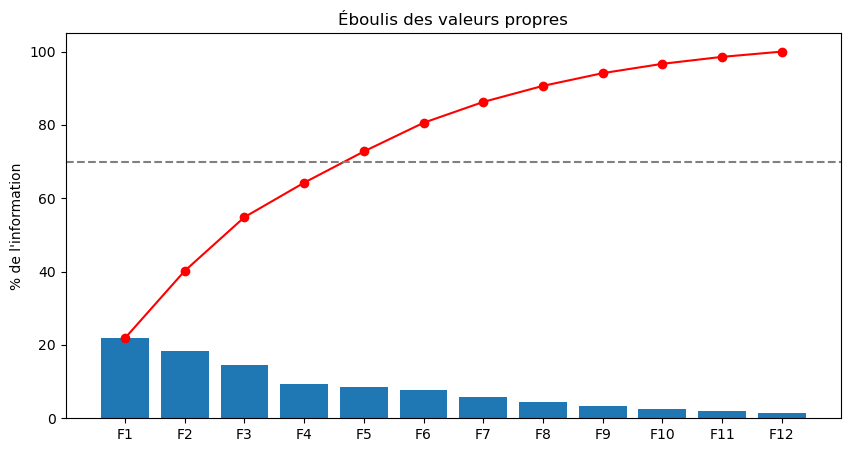

,valeur propre,% information,% cumulé
F1,2.64,21.9,21.9
F2,2.21,18.3,40.2
F3,1.77,14.7,54.9
F4,1.13,9.4,64.2
F5,1.03,8.5,72.8
F6,0.94,7.8,80.6
F7,0.69,5.7,86.3
F8,0.53,4.4,90.7
F9,0.42,3.5,94.1
F10,0.31,2.5,96.7


In [3]:
acp = PCA().fit(X)                                   # l'ACP avec tous les axes (12)

part = acp.explained_variance_ratio_ * 100           # % d'information de chaque axe
cumul = part.cumsum()                                # % cumulé : F1, F1+F2, F1+F2+F3...
noms_axes = [f"F{i}" for i in range(1, 13)]           # F1, F2… F12

plt.figure(figsize=(10, 5))
plt.bar(noms_axes, part)                             # les barres : chaque axe
plt.plot(noms_axes, cumul, color="red", marker="o")  # la courbe : le cumul
plt.axhline(70, color="grey", linestyle="--")        # repère des 70 %
plt.title("Éboulis des valeurs propres")
plt.ylabel("% de l'information")
plt.show()

pd.DataFrame({"valeur propre": acp.explained_variance_.round(2),
              "% information": part.round(1), "% cumulé": cumul.round(1)}, index=noms_axes)

### Je garde 5 axes

* **Critère de Kaiser** : on conserve les axes dont la valeur propre dépasse 1 (qui résument plus qu'une variable de départ), soit les axes F1 à F5 (F5 étant tout juste à 1,03).
* **Le cumul** : 5 axes permettent de conserver 72,8 % de l'information (un sixième axe n'ajoutant que 7,8 %).
* Passage de 12 variables à 5 axes avec moins de 30 % d'information perdue : assez simple pour être lu, assez complet pour ne rien oublier d'important.

## 4. Le cercle des corrélations : que veut dire chaque axe ?

**Lecture du cercle des corrélations** : chaque flèche représente une variable. Plus elle est longue et proche d'un axe, plus elle pèse dans cet axe.

**Corrélation entre variables** : deux flèches longues orientées dans le même sens indiquent des variables qui évoluent ensemble (un pays fort sur l'une l'est généralement aussi sur l'autre).

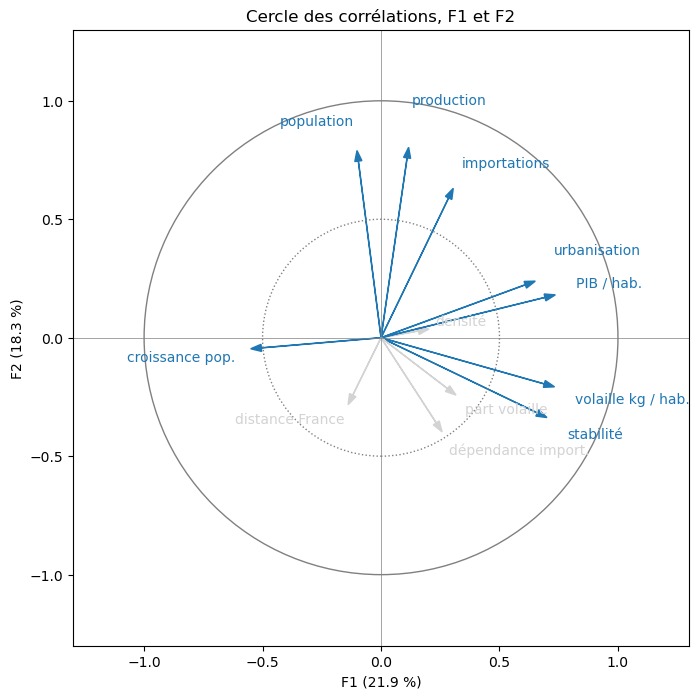

In [4]:
NB_AXES = 5
acp5 = PCA(n_components=NB_AXES).fit(X)          # l'ACP gardée, avec 5 axes
axes_gardes = ["F1", "F2", "F3", "F4", "F5"]

# la place de chaque pays sur les 5 axes (pour la carte et pour les regroupements)
coord_pays = pd.DataFrame(acp5.transform(X), index=pays.index, columns=axes_gardes)

# la corrélation entre chaque variable et chaque axe (le bout de chaque flèche)
correlations = pd.DataFrame(acp5.components_.T * acp5.explained_variance_ ** 0.5,
                            index=pays.columns, columns=axes_gardes)

# des noms courts en français, pour que le cercle se lise sans effort
NOMS = {"population_millions": "population", "croissance_pop_10ans_pct": "croissance pop.",
        "densite_log10": "densité", "pib_hab_ppa": "PIB / hab.", "stabilite_politique": "stabilité",
        "urbanisation_pct": "urbanisation", "distance_france_km": "distance France",
        "volaille_kg_hab": "volaille kg / hab.", "part_volaille_viande_pct": "part volaille",
        "production_volaille_kt": "production", "importations_volaille_kt": "importations",
        "dependance_import_pct": "dépendance import."}

def cercle(axe_x, axe_y):
    fig, ax = plt.subplots(figsize=(8, 8))
    places = []                                                  # où sont déjà écrits les noms
    for variable in correlations.index:                          # une flèche par variable
        x = correlations.loc[variable, axe_x]
        y = correlations.loc[variable, axe_y]
        longueur = (x ** 2 + y ** 2) ** 0.5                      # proche de 1 = bien représentée ici
        couleur = "tab:blue" if longueur >= 0.5 else "lightgrey" # en gris : variable peu visible sur ce plan
        ax.arrow(0, 0, x, y, head_width=0.03, length_includes_head=True, color=couleur)
        tx, ty = x * 1.12, y * 1.12
        while any(abs(tx - a) < 0.35 and abs(ty - b) < 0.07 for a, b in places):   # nom trop près d'un autre :
            ty += 0.07 if y >= 0 else -0.07                                      # je l'écarte un peu du centre
        places.append((tx, ty))
        ax.text(tx, ty, NOMS[variable], fontsize=10, color=couleur,
                ha="left" if x >= 0 else "right", va="bottom" if y >= 0 else "top")
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))               # le cercle de rayon 1
    ax.add_patch(plt.Circle((0, 0), 0.5, fill=False, color="grey", linestyle=":"))  # repère à 0,5
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.set_aspect("equal")                                       # pour que le cercle reste rond
    part_x = acp5.explained_variance_ratio_[axes_gardes.index(axe_x)] * 100
    part_y = acp5.explained_variance_ratio_[axes_gardes.index(axe_y)] * 100
    ax.set_xlabel(f"{axe_x} ({part_x:.1f} %)")
    ax.set_ylabel(f"{axe_y} ({part_y:.1f} %)")
    ax.set_title(f"Cercle des corrélations, {axe_x} et {axe_y}")
    plt.show()

cercle("F1", "F2")

Les flèches en **bleu** sont longues (elles dépassent le cercle pointillé de 0,5) : ces variables
sont bien représentées sur ce plan, je peux les lire. Les flèches en **gris** sont courtes : ces
variables s'expliquent sur d'autres axes, et je ne les interprète pas ici pour ne pas tirer de
fausses conclusions.

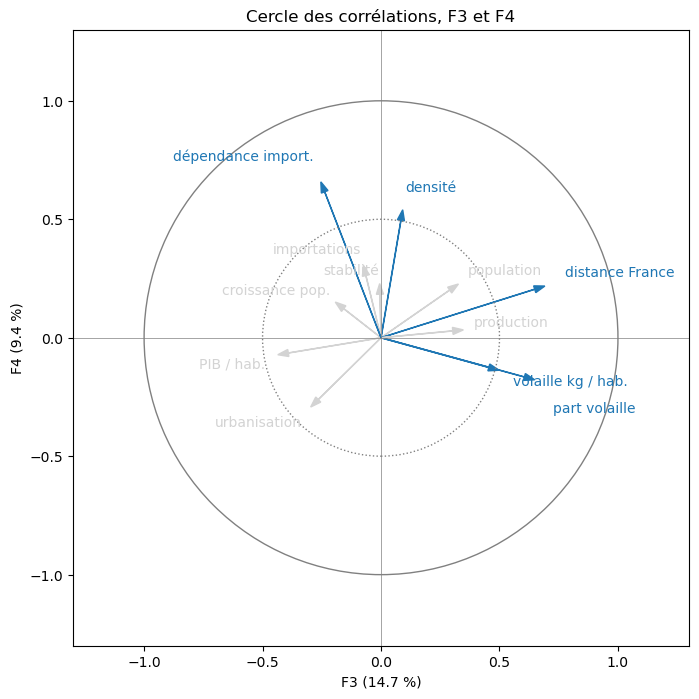

In [5]:
cercle("F3", "F4")

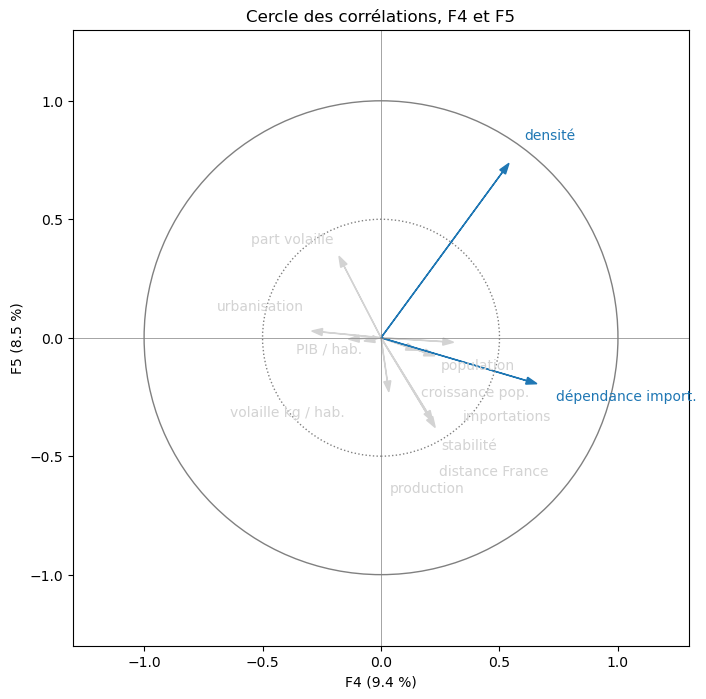

In [6]:
cercle("F4", "F5")

In [7]:
# les mêmes informations en chiffres
correlations.round(2)

,F1,F2,F3,F4,F5
population_millions,-0.10,0.79,0.33,0.23,-0.08
croissance_pop_10ans_pct,-0.55,-0.05,-0.19,0.15,-0.05
densite_log10,0.20,0.04,0.09,0.54,0.74
pib_hab_ppa,0.74,0.18,-0.44,-0.07,-0.01
stabilite_politique,0.70,-0.34,-0.01,0.23,-0.38
urbanisation_pct,0.65,0.24,-0.30,-0.29,0.03
distance_france_km,-0.14,-0.28,0.69,0.22,-0.35
volaille_kg_hab,0.73,-0.21,0.50,-0.14,-0.01
part_volaille_viande_pct,0.32,-0.24,0.65,-0.18,0.34
production_volaille_kt,0.12,0.80,0.35,0.03,-0.23


### Ce que veut dire chaque axe

| Axe | Ce qu'il mesure | Variables qui le portent |
|---|---|---|
| **F1** (21,9 %) | **le niveau de vie** | PIB par habitant (0,74), kilos de volaille par habitant (0,73), stabilité (0,70), urbanisation (0,65) ; à l'opposé, la croissance de la population (-0,55) |
| **F2** (18,3 %) | **la taille du pays** | production de volaille (0,80), population (0,79), importations (0,63) ; à l'opposé, la dépendance aux importations (-0,40, flèche courte : lien léger) |
| **F3** (14,7 %) | **le goût pour la volaille, loin de la France** | distance avec la France (0,69), part de la volaille dans la viande (0,65), kilos par habitant (0,50) ; à l'opposé, le PIB par habitant (-0,44) |
| **F4** (9,4 %) | **les pays denses qui dépendent des importations** | dépendance aux importations (0,66), densité (0,54) |
| **F5** (8,5 %) | **les pays très denses** | densité (0,74) ; à l'opposé, la stabilité (-0,38) et la distance avec la France (-0,35) |

* Sur les cartes de l'étape 5, chaque axe devient une règle : F1 de gauche à droite, F2 de bas en haut (et de même pour F3 et F4). Un pays se place du côté où pointent les flèches des variables sur lesquelles il est fort.
* **Cibles recherchées pour l'export** :
  * **À droite sur F1** : pays riches et stables où vendre du poulet bio plus cher.
  * **Sur F2** : pas de bon côté à lui seul. En haut, il y a à la fois les géants qui produisent (nos concurrents) et les grands importateurs (Royaume-Uni, Pays-Bas) ; en bas, de petits pays qui dépendent des importations mais achètent peu. F2 se lit donc avec F1.
  * **À gauche sur F3** : pays proches pour acheminer un produit frais rapidement.
  * **En haut sur F4** : pays denses qui dépendent déjà des importations.
* F5 sert à décrire le profil démographique (pays très denses ou peu denses) mais n'aide pas à choisir les cibles.
* **Bilan** : les trois grands liens du notebook 1 se retrouvent, et les variables ajoutées jouent pleinement leur rôle (distance sur F3, densité sur F4 et F5).

## 5. La carte des pays

Chaque point sur la carte représente un pays positionné selon ses notes sur les axes. 

Seuls les pays les plus éloignés du centre (ceux qui structurent les axes) et la France (comme repère) sont explicitement affichés pour garder le graphique lisible.

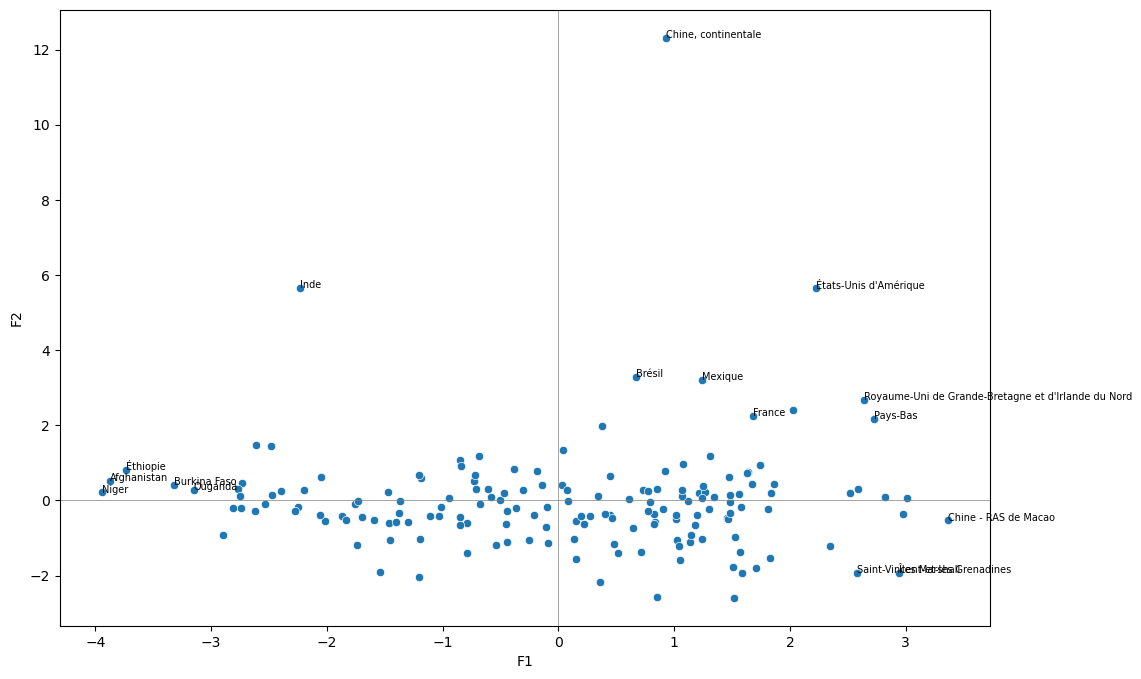

In [8]:
def carte(axe_x, axe_y, couleurs=None):
    plt.figure(figsize=(12, 8))
    if couleurs is None:
        sns.scatterplot(x=coord_pays[axe_x], y=coord_pays[axe_y])
    else:                                                        # une couleur par groupe
        sns.scatterplot(x=coord_pays[axe_x], y=coord_pays[axe_y], hue=couleurs, palette="tab10")
    # distance de chaque pays au centre (théorème de Pythagore ; ** 0.5 = racine carrée)
    distance = (coord_pays[axe_x] ** 2 + coord_pays[axe_y] ** 2) ** 0.5
    a_nommer = list(distance.nlargest(15).index) + ["France"]    # les 15 plus loin + la France
    for nom in a_nommer:
        plt.text(coord_pays.loc[nom, axe_x], coord_pays.loc[nom, axe_y], nom, fontsize=7)
    plt.axhline(0, color="grey", linewidth=0.5)
    plt.axvline(0, color="grey", linewidth=0.5)
    plt.show()

carte("F1", "F2")

**Sur F2** : la Chine, l'Inde, les États-Unis, le Brésil et le Mexique dominent en tant que producteurs massifs de volaille. Ce sont des géants autonomes et non des cibles.

**Sur F1** : les pays riches (Macao, Pays-Bas, Royaume-Uni) se placent à droite, avec les Îles Marshall à cause de leur forte consommation de volaille, tandis que les pays les plus pauvres d'Afrique et d'Asie (Niger, Afghanistan, Éthiopie, Burkina Faso) se trouvent à gauche.

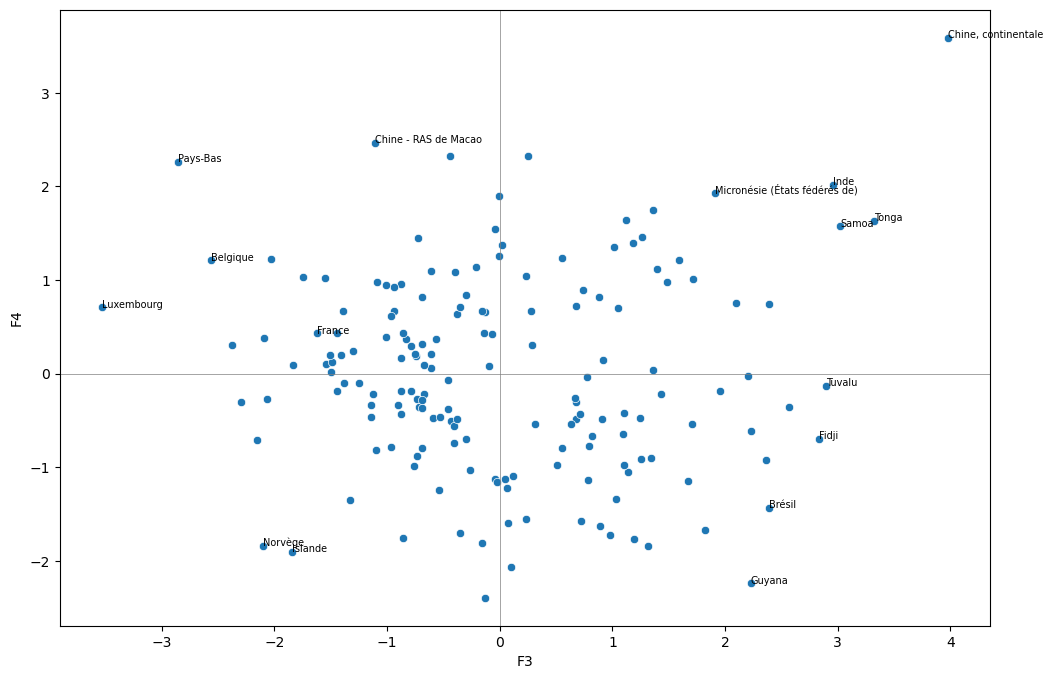

In [9]:
carte("F3", "F4")

**Sur F4** : Macao, les Maldives, Hong Kong et les Pays-Bas se distinguent comme des territoires denses fortement dépendants des importations (la Chine et l'Inde y figurent également en raison de leur volume).

**Sur F3** :

* à droite : des pays lointains où la volaille est la viande principale, comme les îles du Pacifique (Tonga, Samoa, Tuvalu, Fidji), ainsi que la Chine et l'Inde ;
* à gauche : nos voisins proches (Luxembourg, Pays-Bas, Belgique).

## 6. La CAH : combien de groupes faire ?

* **Principe de la CAH** : classification ascendante hiérarchique qui regroupe les pays pas à pas, du pays isolé jusqu'à un groupe unique. Le dendrogramme retrace toutes ces fusions.
* **Données utilisées** : les coordonnées des pays sur les 5 axes de l'ACP (pour garder l'essentiel de l'information en laissant de côté les petits détails).
* **Méthode de Ward** : à chaque étape, elle réunit les deux groupes dont la fusion mélange le moins des pays différents. Elle donne des groupes de taille proche, plus faciles à présenter.

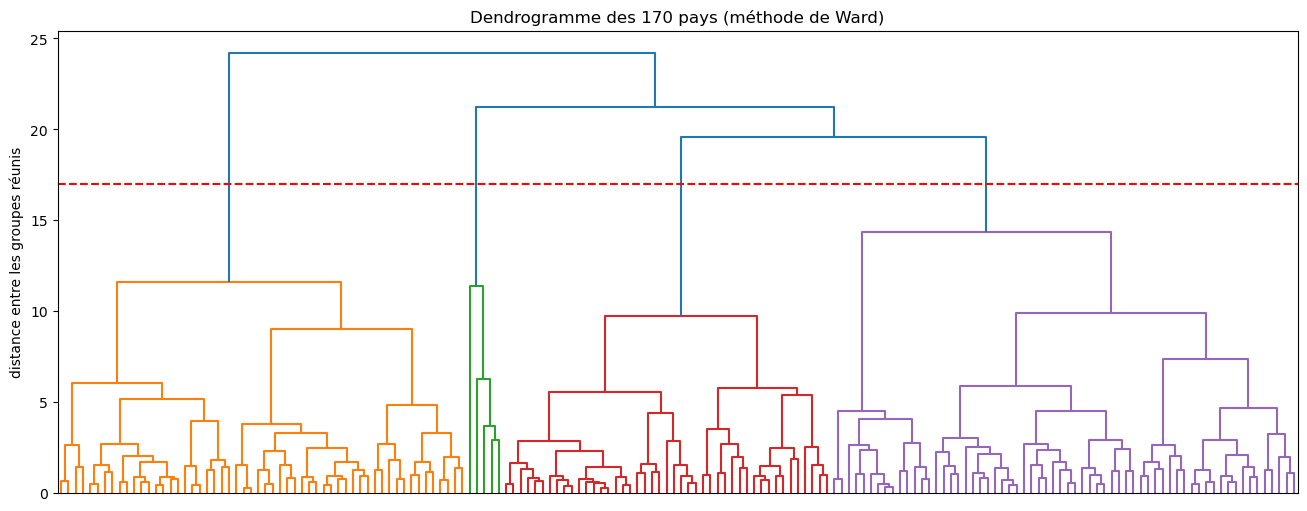

In [10]:
fusions = linkage(coord_pays, method="ward")     # toutes les fusions, de 170 groupes à 1

plt.figure(figsize=(16, 6))
dendrogram(fusions, no_labels=True, color_threshold=17)   # couleurs des branches sous la coupe
plt.axhline(17, color="red", linestyle="--")              # la ligne de coupe
plt.title("Dendrogramme des 170 pays (méthode de Ward)")
plt.ylabel("distance entre les groupes réunis")
plt.show()

### Où couper l'arbre ?

**Principe de la coupe** : plus un pont est haut dans le dendrogramme, plus les groupes réunis sont différents.

**Méthode** : on coupe juste avant le plus grand saut pour éviter de fusionner des pays disparates. Pour plus de précision, la hauteur de ces sauts est mesurée objectivement.

In [11]:
hauteurs = fusions[:, 2]                        # la hauteur de chaque fusion, de la première à la dernière
# le saut quand on passe de k groupes à k - 1 groupes
sauts = {k: hauteurs[-(k - 1)] - hauteurs[-k] for k in range(2, 9)}
pd.Series(sauts, name="saut").round(2)

2    2.98
3    1.69
4    5.20
5    2.79
6    0.22
7    1.48
8    0.14
Name: saut, dtype: float64

**Le choix des 4 groupes** : le plus grand saut de l'arbre se produit entre 4 et 3 groupes (5,20 contre 2,98 au maximum pour les autres coupes), ce qui indique clairement 4 familles de pays.

**Pourquoi pas plus ?** Couper plus bas (5, 6 ou 7 groupes) découpe d'autres familles, mais jamais celle des pays riches : elle garde ses 45 pays (vérifié à l'étape 11). Pour regarder à l'intérieur, il faudra donc un zoom.

In [12]:
NB_GROUPES = 4
pays["groupe_cah"] = fcluster(fusions, NB_GROUPES, criterion="maxclust")   # la famille de chaque pays (1 à 4)
pays["groupe_cah"].value_counts().sort_index()                             # combien de pays par famille

groupe_cah
1    56
2     5
3    45
4    64
Name: count, dtype: int64

In [13]:
# le portrait de chaque famille : la moyenne de chaque variable
VARIABLES = pays.columns.drop("groupe_cah")
VARIABLES_ACP = VARIABLES                         # les 12 variables de départ (resserviront aux étapes 9 et 11)
profil = pays.groupby("groupe_cah")[VARIABLES].mean().round(1)
profil.T

groupe_cah,1,2,3,4
population_millions,34.3,709.0,17.9,21.1
croissance_pop_10ans_pct,24.9,7.5,7.0,8.1
densite_log10,1.8,1.9,2.1,1.9
pib_hab_ppa,7136.9,29370.8,56323.5,20680.6
stabilite_politique,-0.5,-0.5,0.5,0.2
urbanisation_pct,44.6,69.6,76.9,63.3
distance_france_km,7038.6,7774.4,2328.4,8009.0
volaille_kg_hab,8.3,32.6,27.5,38.6
part_volaille_viande_pct,34.0,41.6,36.4,59.3
production_volaille_kt,159.7,14402.8,511.2,554.1


In [14]:
# la liste des pays de chaque famille
for groupe in range(1, NB_GROUPES + 1):
    membres = pays[pays["groupe_cah"] == groupe].index
    print("famille", groupe, ":", len(membres), "pays")
    print(", ".join(membres))
    print()

famille 1 : 56 pays
Afghanistan, Angola, Bangladesh, Bhoutan, Botswana, Burkina Faso, Cambodge, Cameroun, Comores, Congo, Côte d'Ivoire, Djibouti, Eswatini, Gabon, Gambie, Ghana, Guinée, Guinée-Bissau, Haïti, Iraq, Kenya, Kirghizistan, Lesotho, Libéria, Madagascar, Malawi, Maldives, Mauritanie, Mongolie, Mozambique, Myanmar, Namibie, Niger, Nigéria, Oman, Ouganda, Ouzbékistan, Pakistan, Papouasie-Nouvelle-Guinée, Philippines, Rwanda, République démocratique du Congo, République démocratique populaire lao, République-Unie de Tanzanie, Sao Tomé-et-Principe, Sierra Leone, Sénégal, Tadjikistan, Timor-Leste, Turkménistan, Vanuatu, Viet Nam, Zambie, Zimbabwe, Éthiopie, Îles Salomon

famille 2 : 5 pays
Brésil, Chine, continentale, Inde, Mexique, États-Unis d'Amérique

famille 3 : 45 pays
Albanie, Allemagne, Arabie saoudite, Arménie, Autriche, Bahreïn, Belgique, Bulgarie, Chine - RAS de Hong-Kong, Chine - RAS de Macao, Chypre, Croatie, Danemark, Espagne, Estonie, Finlande, France, Fédération d

## 7. Le k-means

**Une deuxième méthode pour vérifier (k-means)** : pour voir si les familles de la CAH tiennent, je refais le regroupement avec le k-means. On place 4 centres, chaque pays rejoint le centre le plus proche, on recalcule les centres, et on recommence jusqu'à ce que plus rien ne bouge.

**Méthode du coude** : l'inertie, c'est l'étalement des pays autour du centre de leur groupe ; plus elle est basse, plus les groupes sont serrés. On cherche le nombre de groupes après lequel elle baisse beaucoup moins.

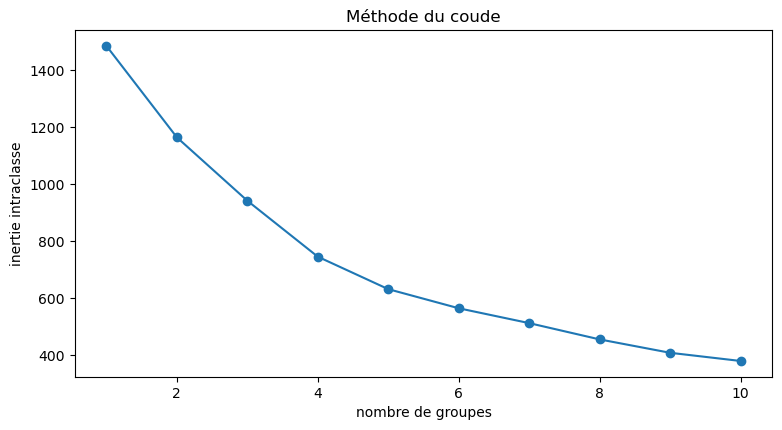

In [15]:
inerties = []
for k in range(1, 11):                                         # de 1 à 10 groupes
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(coord_pays)
    inerties.append(km.inertia_)                               # l'étalement à l'intérieur des groupes

plt.figure(figsize=(9, 4.5))
plt.plot(range(1, 11), inerties, marker="o")
plt.title("Méthode du coude")
plt.xlabel("nombre de groupes")
plt.ylabel("inertie intraclasse")
plt.show()

**Absence de coude net** : les pays forment un ensemble progressif plutôt que des blocs étanches, mais la baisse ralentit autour de 4 groupes.

**Score de silhouette** : évalue la qualité du regroupement (de -1 à +1). Proche de 1, le pays est bien dans son groupe ; proche de 0, il est à la frontière entre deux groupes.

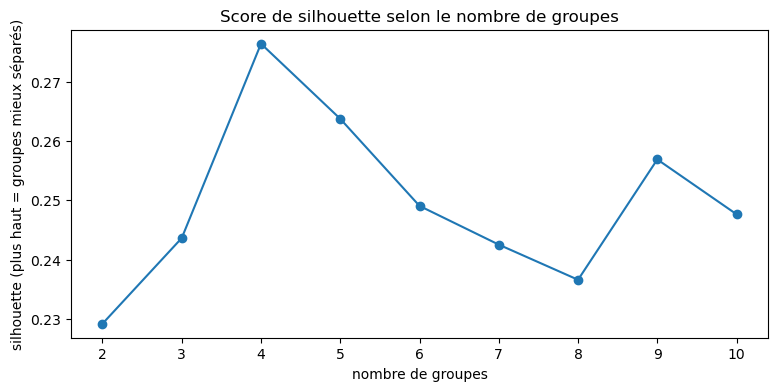

2     0.229
3     0.244
4     0.276
5     0.264
6     0.249
7     0.243
8     0.237
9     0.257
10    0.248
dtype: float64

In [16]:
silhouettes = {}
for k in range(2, 11):
    groupes = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(coord_pays)
    silhouettes[k] = silhouette_score(coord_pays, groupes)    # la moyenne sur les 170 pays

plt.figure(figsize=(9, 4))
plt.plot(list(silhouettes), list(silhouettes.values()), marker="o")
plt.title("Score de silhouette selon le nombre de groupes")
plt.xlabel("nombre de groupes")
plt.ylabel("silhouette (plus haut = groupes mieux séparés)")
plt.show()
pd.Series(silhouettes).round(3)

**Meilleur score** : 4 groupes (0,276) devant 5 (0,264). Scores modestes (< 0,3) en raison des transitions progressives entre pays.

**Validation finale** : je garde 4 groupes, comme la CAH : c'est le plus grand saut de l'arbre, c'est la meilleure silhouette, et cela me permet de comparer les deux méthodes à nombre égal.

In [17]:
# random_state=42 : toujours le même résultat ; n_init=20 : 20 essais, il garde le meilleur
kmeans = KMeans(n_clusters=NB_GROUPES, n_init=20, random_state=42).fit(coord_pays)
pays["groupe_kmeans"] = kmeans.labels_           # le groupe de chaque pays (numérotés de 0 à 3)
pays["groupe_kmeans"].value_counts().sort_index()

groupe_kmeans
0     5
1    56
2    59
3    50
Name: count, dtype: int64

### Les centroïdes : le centre de chaque groupe

**Le centroïde** : point moyen de chaque groupe du k-means représentant un « pays type ».

**Positionnement** : affichés sous forme de croix noires sur la carte F1-F2, ils matérialisent le point d'attraction auquel chaque pays est rattaché selon sa proximité.

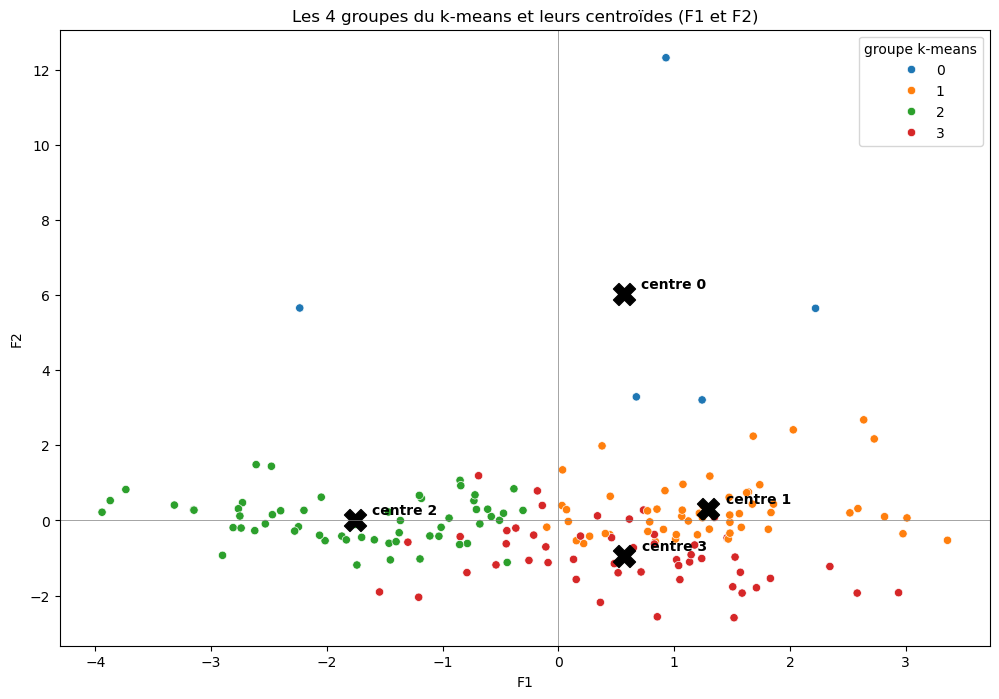

In [18]:
centres = pd.DataFrame(kmeans.cluster_centers_, columns=axes_gardes)   # un centroïde par groupe

plt.figure(figsize=(12, 8))
sns.scatterplot(x=coord_pays["F1"], y=coord_pays["F2"], hue=pays["groupe_kmeans"].astype(str), palette="tab10",
                hue_order=[str(g) for g in range(NB_GROUPES)])
plt.scatter(centres["F1"], centres["F2"], marker="X", s=250, color="black")   # les centroïdes
for numero, ligne in centres.iterrows():
    plt.text(ligne["F1"] + 0.15, ligne["F2"] + 0.15, f"centre {numero}", fontsize=10, weight="bold")
plt.axhline(0, color="grey", linewidth=0.5)
plt.axvline(0, color="grey", linewidth=0.5)
plt.title("Les 4 groupes du k-means et leurs centroïdes (F1 et F2)")
plt.legend(title="groupe k-means")
plt.show()

**Le centroïde des 5 géants** : situé tout en haut, très à l'écart, il structure l'axe F2.

**Le centroïde des pays riches** : à droite sur F1.

**Le centroïde des pays pauvres** : à gauche sur F1.

**Le quatrième centroïde** : proche du centre sur F1 et F2, ses pays se distinguent principalement sur les axes F3 à F5.

## 8. Les deux méthodes donnent-elles les mêmes groupes ?

**Le tableau croisé** : il croise les familles de la CAH (lignes) et les groupes du k-means (colonnes), pour voir si les deux méthodes rangent les pays de la même façon.

**Lecture** : les numéros de groupes différant d'une méthode à l'autre, on vérifie simplement que chaque ligne présente une concentration forte (une « grosse case »), signe d'un accord net entre les deux approches.

In [19]:
croisement = pd.crosstab(pays["groupe_cah"], pays["groupe_kmeans"])
croisement

groupe_kmeans,0,1,2,3
groupe_cah,,,,
1,0,2,47,7
2,5,0,0,0
3,0,45,0,0
4,0,9,12,43


In [20]:
# pour chaque famille de la CAH, la case la plus remplie = les pays rangés ensemble par les deux méthodes
accord = croisement.max(axis=1).sum() / len(pays) * 100
print("les deux méthodes rangent ensemble", round(accord), "% des pays")

les deux méthodes rangent ensemble 82 % des pays


**Les deux méthodes sont d'accord** pour **82 % des pays**, surtout pour les plus importants :
  * Les **45 pays riches** restent bien ensemble (avec 11 pays au profil voisin en plus, comme le Canada, la Turquie ou Israël).
  * Les **5 géants** (Brésil, Chine, Inde, Mexique, États-Unis) restent isolés dans les deux classements.

**Les petits désaccords** : ils concernent des pays « frontières » entre les pays pauvres et la 4e famille (la CAH fige les choix au fur et à mesure, alors que le k-means peaufine les groupes jusqu'à la fin).

**Choix final** : on garde les groupes de la CAH, car ils sont plus faciles à expliquer avec l'arbre pour présenter le projet.

## 9. Et avec une autre mise à l'échelle ?

**Le problème potentiel** : la moyenne et l'écart-type classiques peuvent être perturbés par les valeurs extrêmes (Chine, Inde, Hong Kong).

**La solution testée** : une mise à l'échelle robuste (basée sur la médiane et l'écart interquartile), moins sensible aux pays extrêmes.

**Le test** : refaire toute la chaîne (ACP à 5 axes, CAH à 4 groupes) avec cette méthode pour comparer la taille des groupes obtenus.

In [21]:
X_robuste = RobustScaler().fit_transform(pays[VARIABLES_ACP])          # (valeur - médiane) / écart interquartile
coord_robuste = PCA(n_components=NB_AXES).fit_transform(X_robuste)
groupes_robustes = fcluster(linkage(coord_robuste, method="ward"), NB_GROUPES, criterion="maxclust")

pd.Series(groupes_robustes).value_counts()        # combien de pays dans chaque groupe

1    166
2      2
3      1
4      1
Name: count, dtype: int64

In [22]:
# qui sont les pays des petits groupes ?
robustes = pd.Series(groupes_robustes, index=pays.index)
for groupe in robustes.value_counts().index[1:]:          # tous les groupes sauf le plus gros
    print(groupe, ":", ", ".join(robustes[robustes == groupe].index))

2 : Brésil, États-Unis d'Amérique
3 : Chine, continentale
4 : Inde


**Le résultat du test robuste** : 166 pays sur 170 se retrouvent dans le même groupe (seuls les États-Unis avec le Brésil, la Chine et l'Inde sont isolés à part). Ce résultat est inexploitable pour présenter des options claires à la direction.

**Pourquoi ?** La médiane et l'écart interquartile se focalisent uniquement sur les pays « du milieu », ce qui fait paraître les extrêmes (les géants) si lointains qu'ils écrasent toute la structure sur l'ACP.

**Conclusion** : on garde le centrage-réduction classique, qui donne des familles équilibrées et lisibles. Les valeurs extrêmes ne gênent pas les résultats :
  * La densité est passée en logarithme (notebook 1).
  * Les 5 géants forment leur propre famille dans la CAH, au lieu de déformer les autres.

## 10. Le portrait des 4 familles de pays

Maintenant que j'ai mes 4 familles, je veux savoir qui elles sont. Je compare chaque famille à la
moyenne des 170 pays : en vert, elle est au-dessus de la moyenne ; en rouge, en dessous. Les chiffres
écrits dans les cases sont les vraies moyennes de la famille.

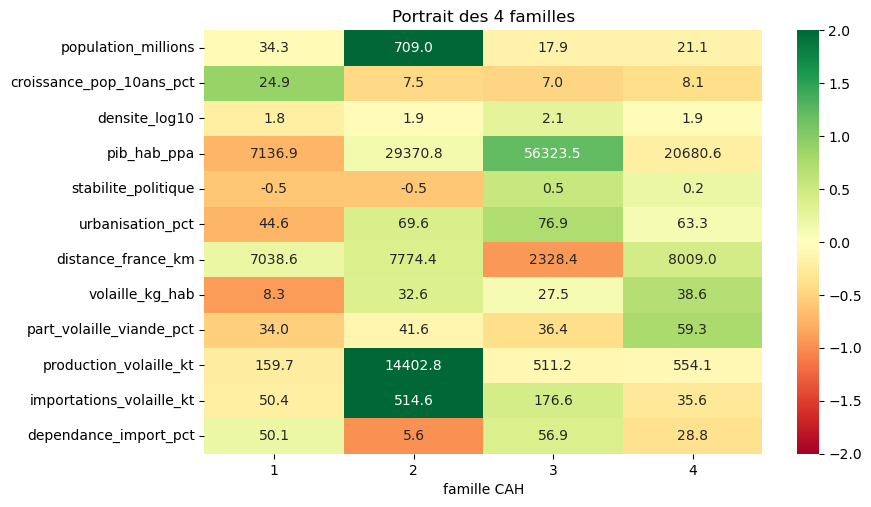

In [23]:
# écart à la moyenne, en écarts-types (pour que les couleurs soient comparables d'une variable à l'autre)
ecarts = (profil - pays[VARIABLES].mean()) / pays[VARIABLES].std()

plt.figure(figsize=(9, 5.5))
sns.heatmap(ecarts.T, annot=profil.T, fmt=".1f", cmap="RdYlGn", center=0, vmin=-2, vmax=2)
plt.title("Portrait des 4 familles")
plt.xlabel("famille CAH")
plt.show()

La densité est en logarithme : 1,8 veut dire environ 60 habitants au km², 2,0 environ 100.

### Le radar : le profil de chaque famille d'un coup d'œil

**Le besoin** : alléger le tableau pour le comité de direction en le traduisant en graphiques radar par famille.

**Le principe** : chaque axe correspond à une variable clé ; plus le point est loin du centre, plus la famille est haute sur cette variable ; au-delà du pointillé, elle dépasse la moyenne des 170 pays. Les valeurs sont bloquées à 2 écarts-types pour que les géants n'écrasent pas le dessin.

**La sélection** : conservation de **8 variables essentielles** pour orienter la décision d'exportation.

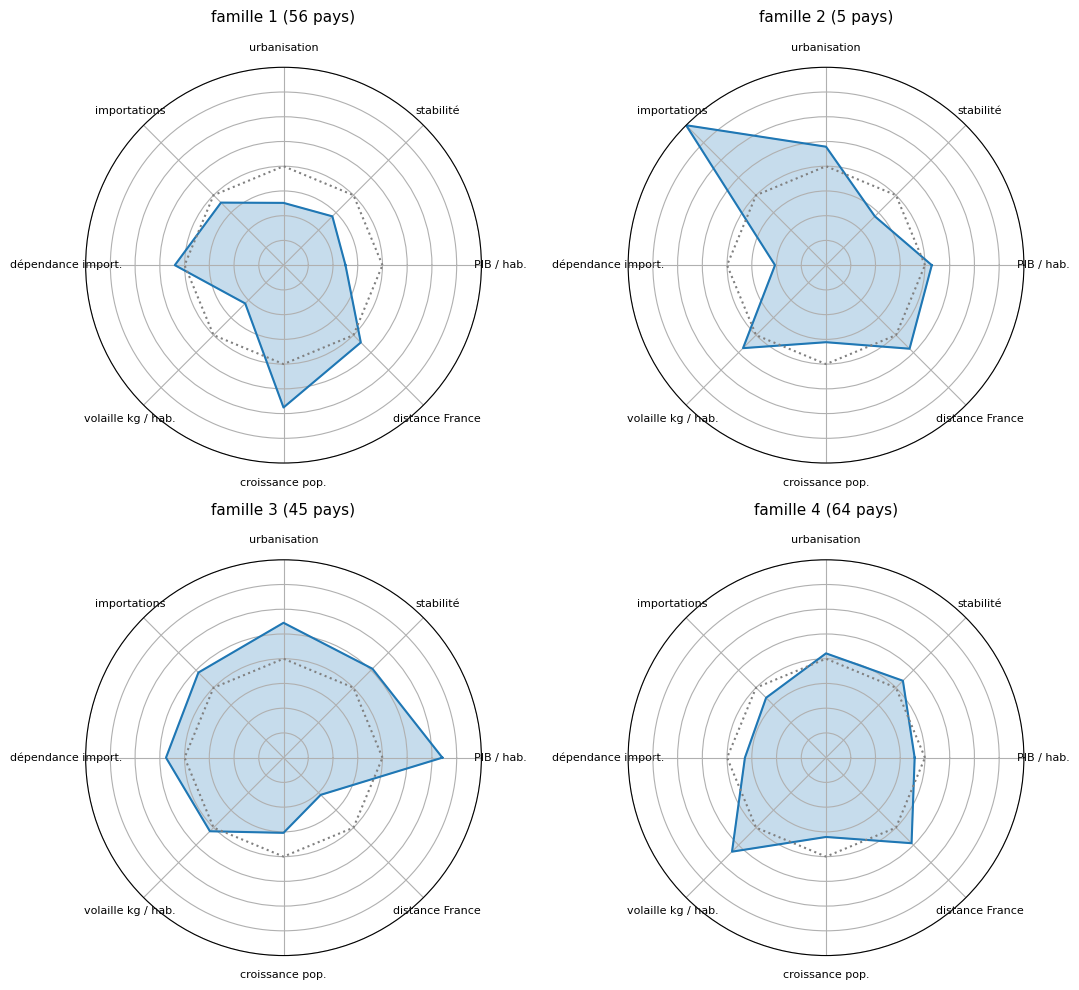

In [24]:
RADAR = ["pib_hab_ppa", "stabilite_politique", "urbanisation_pct", "importations_volaille_kt",
         "dependance_import_pct", "volaille_kg_hab", "croissance_pop_10ans_pct", "distance_france_km"]
angles = np.linspace(0, 2 * np.pi, len(RADAR), endpoint=False).tolist()
angles += angles[:1]                                  # on referme la forme

def radar(ax, valeurs, titre):
    valeurs = list(valeurs.clip(-2, 2)) + [valeurs.clip(-2, 2).iloc[0]]
    ax.plot(angles, valeurs, color="tab:blue")
    ax.fill(angles, valeurs, color="tab:blue", alpha=0.25)
    ax.plot(angles, [0] * len(angles), color="grey", linestyle=":")    # le cercle de la moyenne
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([NOMS[v] for v in RADAR], fontsize=8)
    ax.set_ylim(-2, 2)
    ax.set_yticklabels([])
    ax.set_title(titre, fontsize=11, pad=15)

fig, axes = plt.subplots(2, 2, figsize=(11, 10), subplot_kw={"polar": True})
for ax, groupe in zip(axes.flat, ecarts.index):
    radar(ax, ecarts.loc[groupe, RADAR], f"famille {groupe} ({(pays['groupe_cah'] == groupe).sum()} pays)")
plt.tight_layout()
plt.show()

Le pointillé est la moyenne des 170 pays.

**Famille 3** : dépasse la moyenne sur le PIB, l'urbanisation, la stabilité et les importations, avec une position géographique proche de la France. C'est notre cible prioritaire.

**Famille 1** : en dessous de la moyenne sur presque tous les critères, hormis la croissance démographique.

**Famille 2 (les géants)** : affiche de gros volumes d'importation en valeur absolue en raison de sa taille, mais une dépendance quasi nulle (autosuffisance de la production locale).

**Famille 4** : se distingue par une forte consommation de volaille et une grande distance géographique (gros consommateurs lointains).

### La carte des familles et de leurs centroïdes
**Reprise de la carte F1-F2** avec un code couleur par famille.

**Les centroïdes** (le point moyen de chaque famille) montrent où se place chaque famille sur la carte F1-F2. Ce n'est pas une carte du monde : deux pays proches sur la carte ont des profils proches, pas des frontières communes.

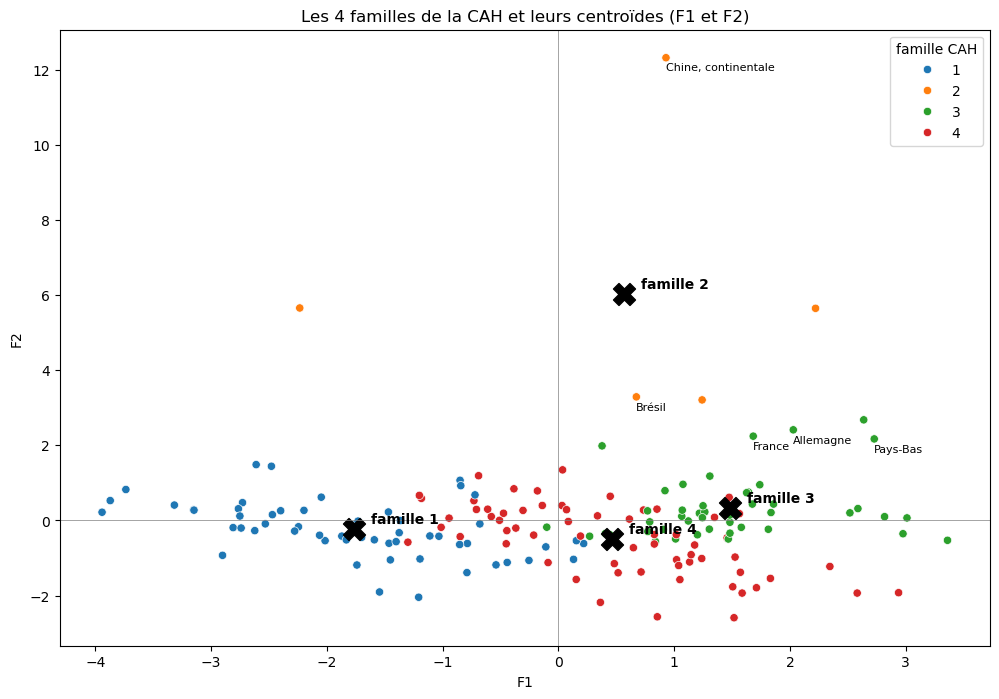

In [25]:
centres_cah = coord_pays.groupby(pays["groupe_cah"]).mean()      # le centre de chaque famille

plt.figure(figsize=(12, 8))
sns.scatterplot(x=coord_pays["F1"], y=coord_pays["F2"], hue=pays["groupe_cah"].astype(str), palette="tab10",
                hue_order=[str(g) for g in range(1, NB_GROUPES + 1)])
plt.scatter(centres_cah["F1"], centres_cah["F2"], marker="X", s=250, color="black")
for groupe, ligne in centres_cah.iterrows():
    plt.text(ligne["F1"] + 0.15, ligne["F2"] + 0.15, f"famille {groupe}", fontsize=10, weight="bold")
for nom in ["France", "Allemagne", "Pays-Bas", "Chine, continentale", "Brésil"]:   # quelques repères
    plt.text(coord_pays.loc[nom, "F1"], coord_pays.loc[nom, "F2"] - 0.35, nom, fontsize=8)
plt.axhline(0, color="grey", linewidth=0.5)
plt.axvline(0, color="grey", linewidth=0.5)
plt.title("Les 4 familles de la CAH et leurs centroïdes (F1 et F2)")
plt.legend(title="famille CAH")
plt.show()

Les centres des familles se placent comme ceux du k-means : les géants en haut, les riches à droite, les pauvres à gauche, la famille 4 près du milieu. La France, l'Allemagne et les Pays-Bas sont dans la famille 3.

### Les 4 familles en clair

**Synthèse des 4 familles** :

* **Famille 3 (45 pays riches et stables)** : PIB élevé (56 000 dollars par habitant), proximité géographique (2 300 km). **C'est notre cible prioritaire.**
* **Famille 1 (56 pays pauvres)** : PIB faible (7 100 dollars par habitant), instables, non ciblés (notamment pour un positionnement qualité et bio).
* **Famille 2 (5 géants)** : Brésil, Chine, Inde, Mexique, États-Unis ; ils produisent eux-mêmes, ce sont nos concurrents.
* **Famille 4 (64 pays intermédiaires)** : revenus moyens, éloignement géographique important (8 000 km en moyenne).

**Le problème de la famille 3** : 45 pays, c'est trop large pour une stratégie d'export opérationnelle, d'autant que les situations y sont très contrastées (par exemple, l'Allemagne importe 52 % de ses besoins en volaille, tandis que la Pologne n'en importe que 6 %).

**Prochaine étape** : effectuer un zoom à l'intérieur de cette grande famille 3 pour différencier ces marchés et cibler précisément les pays acheteurs les plus rentables.

## 11. Le zoom sur la famille des pays riches

La CAH est **hiérarchique** : chaque famille est elle-même faite de sous-groupes, qui se séparent
plus bas dans l'arbre. Je relance donc une CAH **sur les 45 pays riches seulement**, et je mesure les
sauts de ce nouvel arbre, exactement comme à l'étape 6.

2    3.97
3    0.23
4    0.16
5    1.00
6    0.86
Name: saut, dtype: float64


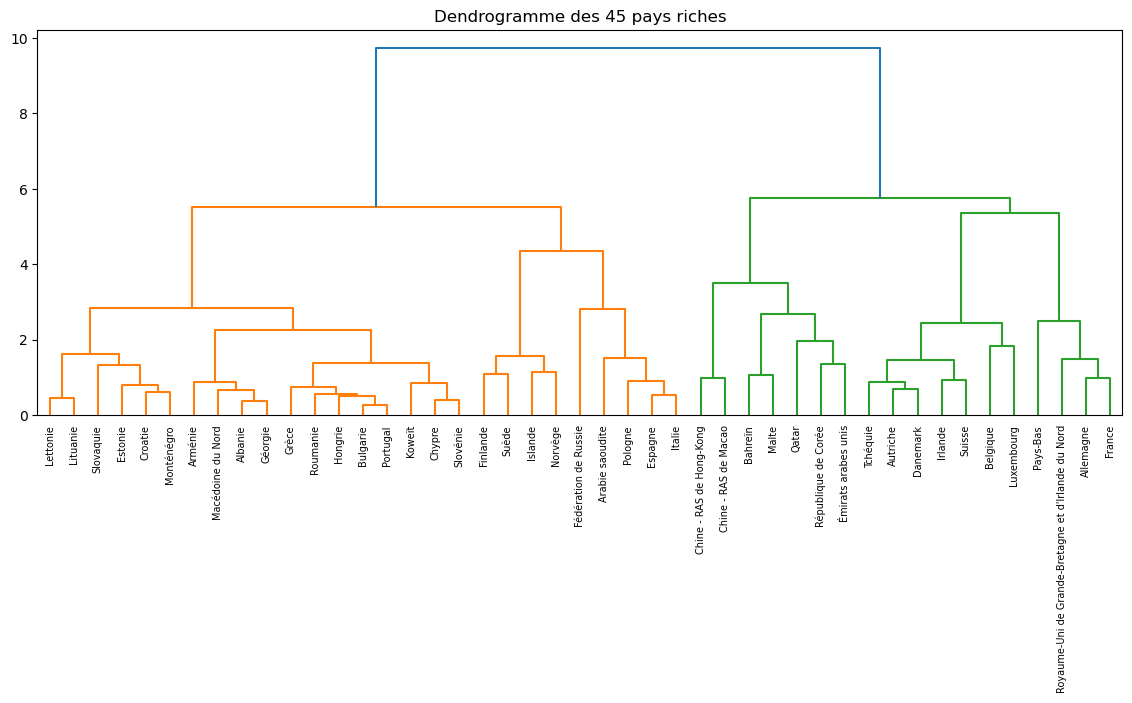

sous_groupe,1.0,2.0
population_millions,16.3,20.3
croissance_pop_10ans_pct,2.7,13.5
densite_log10,1.7,2.6
pib_hab_ppa,44013.5,74788.5
stabilite_politique,0.4,0.7
urbanisation_pct,70.3,86.8
distance_france_km,1979.1,2852.2
volaille_kg_hab,26.8,28.5
part_volaille_viande_pct,37.2,35.1
production_volaille_kt,549.1,454.3


In [26]:
famille_riche = pays.loc["Allemagne", "groupe_cah"]                   # la famille des pays riches
riches = pays[pays["groupe_cah"] == famille_riche].index

fusions_riches = linkage(coord_pays.loc[riches], method="ward")        # une CAH sur les 45 pays seulement

hauteurs_riches = fusions_riches[:, 2]                                 # les sauts, comme à l'étape 6
print(pd.Series({k: hauteurs_riches[-(k - 1)] - hauteurs_riches[-k] for k in range(2, 7)}, name="saut").round(2))

pays.loc[riches, "sous_groupe"] = fcluster(fusions_riches, 2, criterion="maxclust")   # le plus grand saut : 2

plt.figure(figsize=(14, 5))
dendrogram(fusions_riches, labels=list(riches), leaf_font_size=7, color_threshold=fusions_riches[-1, 2] - 0.01)
plt.title("Dendrogramme des 45 pays riches")
plt.show()

# le portrait des 2 sous-groupes
pays.loc[riches].groupby("sous_groupe")[VARIABLES].mean().round(1).T

In [27]:
for sous in [1, 2]:
    membres = pays[pays["sous_groupe"] == sous].index
    print("sous-groupe", sous, ":", len(membres), "pays")
    print(", ".join(membres))
    print()

sous-groupe 1 : 27 pays
Albanie, Arabie saoudite, Arménie, Bulgarie, Chypre, Croatie, Espagne, Estonie, Finlande, Fédération de Russie, Grèce, Géorgie, Hongrie, Islande, Italie, Koweït, Lettonie, Lituanie, Macédoine du Nord, Monténégro, Norvège, Pologne, Portugal, Roumanie, Slovaquie, Slovénie, Suède

sous-groupe 2 : 18 pays
Allemagne, Autriche, Bahreïn, Belgique, Chine - RAS de Hong-Kong, Chine - RAS de Macao, Danemark, France, Irlande, Luxembourg, Malte, Pays-Bas, Qatar, Royaume-Uni de Grande-Bretagne et d'Irlande du Nord, République de Corée, Suisse, Tchéquie, Émirats arabes unis



In [28]:
# vérification : en coupant l'arbre de départ plus bas, la famille des pays riches se coupe-t-elle ?
for k in [5, 6, 7]:
    coupe = pd.Series(fcluster(fusions, k, criterion="maxclust"), index=pays.index)
    print(k, "groupes : la famille de l'Allemagne compte", (coupe == coupe["Allemagne"]).sum(), "pays")

5 groupes : la famille de l'Allemagne compte 45 pays
6 groupes : la famille de l'Allemagne compte 45 pays
7 groupes : la famille de l'Allemagne compte 45 pays


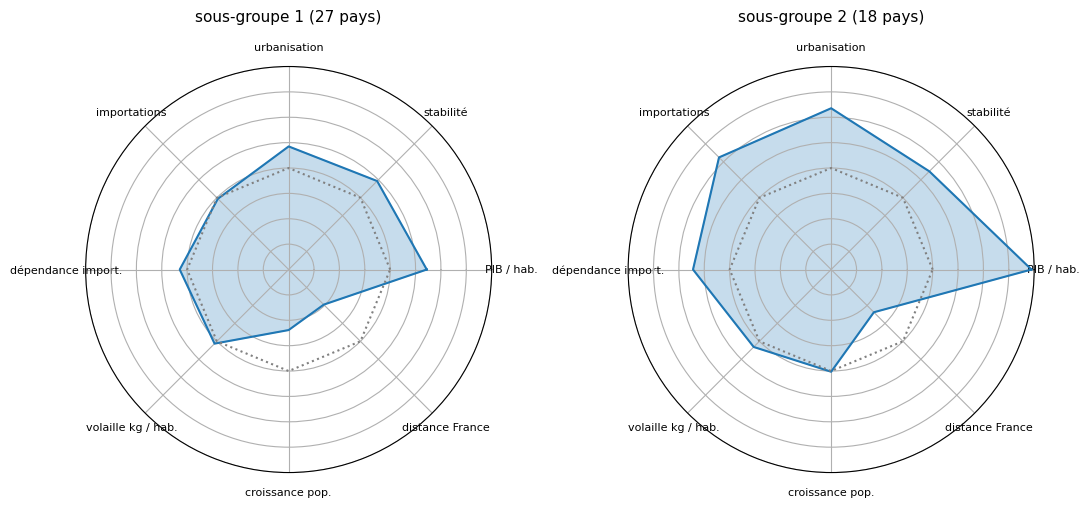

In [29]:
# les deux sous-groupes sur le radar, par rapport à la moyenne des 170 pays
ecarts_riches = (pays.loc[riches].groupby("sous_groupe")[VARIABLES].mean() - pays[VARIABLES].mean()) / pays[VARIABLES].std()
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), subplot_kw={"polar": True})
for ax, sous in zip(axes, ecarts_riches.index):
    radar(ax, ecarts_riches.loc[sous, RADAR], f"sous-groupe {int(sous)} ({(pays['sous_groupe'] == sous).sum()} pays)")
plt.tight_layout()
plt.show()

**Le zoom sur la famille 3** : un nouveau découpage hiérarchique (le plus grand saut du nouvel arbre est entre 2 sous-groupes et 1 : 3,97, contre 1,00 au plus pour les autres coupes, donc je coupe en 2) sépare nettement les 45 pays riches en deux blocs distincts :

**Les 18 grands importateurs** : PIB par habitant très élevé (75 000 dollars), dépendants des achats extérieurs à hauteur de **70 %** (en moyenne 312 000 tonnes importées). Ce bloc regroupe l'Europe du Nord et de l'Ouest (Allemagne, Pays-Bas, Royaume-Uni, France, Suisse, etc.), ainsi que des hubs clés comme Hong Kong, Macao, la Corée et le Golfe (Émirats, Qatar, Bahreïn).

**Les 27 pays qui produisent davantage eux-mêmes** : l'Europe du Sud, de l'Est et du Nord (Pologne, Espagne, Italie, Suède, Finlande), la Russie ou l'Arabie saoudite. Ils importent 48 % de leur volaille, 86 000 tonnes en moyenne.

**Validation méthodologique** : couper l'arbre général en 5, 6 ou 7 groupes n'aurait pas fonctionné (la grande famille serait restée bloquée à 45). Le zoom était donc le moyen le plus simple d'isoler ce sous-groupe.

**Cible finale validée** : le sous-groupe des **18 importateurs massifs et riches** constitue notre terrain d'action prioritaire pour l'exportation.

## 12. Les pays à recommander

Je pars des 18 pays riches importateurs, sans la France puisque c'est déjà notre marché, et je les
classe par volume de volaille déjà importé : plus un pays importe, plus la place à prendre est
grande.

In [30]:
sous_importateur = pays.loc["Allemagne", "sous_groupe"]               # le sous-groupe des importateurs
cibles = pays[(pays["sous_groupe"] == sous_importateur) & (pays.index != "France")]
colonnes = ["importations_volaille_kt", "dependance_import_pct", "pib_hab_ppa", "stabilite_politique",
            "distance_france_km", "population_millions"]
cibles[colonnes].sort_values("importations_volaille_kt", ascending=False).round(1)

,importations_volaille_kt,dependance_import_pct,pib_hab_ppa,stabilite_politique,distance_france_km,population_millions
Zone,,,,,,
Royaume-Uni de Grande-Bretagne et d'Irlande du Nord,978.0,35.6,53423.4,0.4,342.8,68.7
Pays-Bas,901.0,100.0,70199.0,0.6,430.1,18.1
Allemagne,777.0,51.5,63140.2,0.5,878.0,84.5
Émirats arabes unis,611.0,100.0,70239.8,0.8,5239.0,10.6
Chine - RAS de Hong-Kong,327.0,100.0,64387.7,0.5,9626.4,7.4
République de Corée,294.0,23.1,54029.3,0.9,8967.9,51.7
Belgique,285.0,100.0,63042.0,0.2,263.4,11.7
Tchéquie,150.0,53.6,47558.4,1.1,881.7,10.8
Autriche,122.0,68.5,64536.2,0.7,1033.7,9.1


* **Première vague (Cibles prioritaires)** :
  * **Allemagne** : premier marché bio d'Europe (selon le rapport annuel du FiBL et de l'IFOAM, *The World of Organic Agriculture*), grand importateur au sein de l'UE, voisin direct. **Cœur de cible idéal pour démarrer.**
  * **Royaume-Uni** : volume d'importation massif, mais contraintes douanières post-Brexit.
  * **Pays-Bas** : importateur majeur et hub logistique (port de Rotterdam) servant de passerelle vers le reste de l'Europe.

* **Deuxième vague (Marchés européens secondaires)** :
  * **Belgique** (dépendance totale aux importations).
  * **Petits marchés stables** : Tchéquie, Autriche, Irlande, Danemark, Suisse et Luxembourg.

* **Pistes à explorer ultérieurement** :
  * **Pays du Golfe** (Émirats, Qatar, Bahreïn) : fort pouvoir d'achat et volumes élevés, mais nécessite une étude spécifique sur la certification halal et la concurrence brésilienne.
  * **Asie** (Hong Kong, Corée, Macao) : éloignement (environ 9 000 km ou plus) incompatible avec le frais, réservé à une offre surgelée.
  * **Japon** : absent du bilan FAO 2023 (la FAO revoit ses chiffres). Il était le premier importateur de volaille dans les données 2017 : à réexaminer dès que la FAO publiera ses chiffres.

## Synthèse générale de la stratégie d'exportation de volaille

* **1. Réduction de dimension (ACP)** : 12 variables résumées en 5 axes qui gardent 72,8 % de l'information (niveau de vie, taille, préférences de consommation, dépendance aux importations et densité).
* **2. Segmentation (CAH et k-means)** : regroupement validé en **4 familles**, confirmé par le plus grand saut de l'arbre et un accord de 82 % avec le k-means (test robuste écarté au profit du centrage-réduction classique).
* **3. Le zoom** : dans la famille riche, **18 pays importent 70 % de leur volaille** (17 hors France).
* **4. Plan d'action et priorisation** :
  * **Priorité 1** : Allemagne (marché bio, proximité, pas de barrière douanière), Pays-Bas (hub logistique) et Royaume-Uni (volume, contraintes post-Brexit).
  * **Priorité 2** : Belgique et petits marchés européens stables (Suisse, Danemark, Autriche, etc.).
* **5. Limites et vigilance** : une seule année (2023), peut-être encore marquée par les crises (Covid, grippe aviaire), où manquent quelques pays (surtout le Japon) ; rien sur la demande en bio, les prix, les droits de douane, la température (conservation du frais) ou la concurrence locale ; et, avant d'entrer dans un pays, il faudra vérifier les règles sanitaires, la grippe aviaire et les embargos, en commençant par l'Allemagne.